# Quantum Metal 52 — Barends-style five-qubit linear Xmon processor (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal circuit example
`docs/circuit-examples/F.Small-quantum-chips/52-Barends_5Qubit_Xmon_Processor.ipynb` (© IBM / Qiskit Metal
contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/52_barends_5q.md`). It adapts the QDW 2026 capstone solution by M. C. Sarihan after Barends
*et al.*, Nature 508, 500 (2014), and calls itself "a physical-layout example inspired by the published device, not
the fabricated mask". The id is prefixed `m` (ids do not start with a digit). We distribute the rebuild under GPL-3.0.

Five `TransmonCrossFL` Xmons in a line at 450 µm pitch, close enough that their ground pockets merge: neighbours
couple directly through their facing cross arms (no bus resonators). Each has a λ/4 meander readout (4.41 … 4.57 mm
in 40 µm steps, for distinct multiplexed tones) shorted at a `CoupledLineTee`; the five tees sit on one feedline
whose section between two `CapNInterdigital` series capacitors is the common Purcell filter. Each qubit has an XY
drive line ending open (`OpenToGround`) beside its cross and a Z flux line, each to its own edge
`LaunchpadWirebond` (12 pads, 3 per edge).

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the source's own options, but the chip, the
stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example 52 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 6 × 6 mm centred on (0, 0); the launchpads overhang it (6.2 × 6.2 mm drawn) | the standard 7.5 × 7.5 mm Quantcore die with the QCT frame, the source's area centred in it (`P(x, y)` = Metal + (3750, 3750)) |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 12 `LaunchpadWirebond`s at ±2.8 mm, ≈ 650 µm in from our die edge | the same pads moved to **100 µm** (`frame.pad_edge`) from the die edge; every line keeps its path, its last straight gets longer |
| junctions | none in the GDS (no junction file, no `hfss_inductance`) | a Quantcore trilayer SQUID per qubit: two 0.25 × 0.6 µm junctions, R_n 45 kΩ in parallel, L_J 6.73 nH at zero flux |
| cheese | **yes**: the notebook exports GDS with Metal's renderer at its defaults (25 µm squares every 100 µm, `no_cheese.buffer` 25 µm, 200 µm edge band) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule()`) |
| routes | `RouteStraight` / `RouteAnchors` feedline, `RouteMeander` readouts, `RouteFramed` XY / Z lines | qcc `cpw` routes through Metal's corner points, so the lengths are Metal's (readouts 4410 … 4570 µm) |
| placement | as drawn | centred in the die (it already is: the source is symmetric) |

**Kept exactly:** every component with the source's options, positions and orientations; every route's end pins;
the feedline (Metal's `RouteStraight`s and the two `RouteAnchors` paths, fillets 100 / 20 µm) and the ten XY / Z
control lines (the `RouteFramed` paths with their jogs, fillet 20 µm) as waypoints at Metal's corner points. All
routes are 10/6 µm CPW, as in the source (the Z line steps down to the 5/3 µm flux-line pin).

**Simplified:** the readout meanders are Metal's (150 µm lead, 14 runs at 50 µm spacing from y = 451 to 1101 µm,
fillet 20 µm) except the last 32 µm jog to the tee leg, which is shorter than two 20 µm fillets in the qcc router:
the last run ends at the leg instead, and the run half-width grows by ≈ 2 µm so that each resonator keeps Metal's
total length.

**Assumed coupling:** neighbouring cross arms face each other end-on across 70 µm (450 µm pitch − 2 × 190 µm arms).
No route carries this, so it is declared with `d.couple` from a coplanar-strip estimate (rough). The Q3D C-matrix
job `chain` replaces it.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

Two helpers are this chip's own: `P(x, y)` maps a Metal position (its chip is centred on (0, 0)) onto the die, and
`readout_path` rebuilds Metal's `RouteMeander` readout as corner points, solving the run half-width so the filleted
length is the source's.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom import estimates as est
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 3750, 3750                              # Metal's 6 × 6 mm chip is centred on (0, 0); our die is 7.5 mm
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PP = lambda pts: [P(x, y) for x, y in pts]
PITCH = 450                                      # qubit pitch (Metal qubit_pitch 0.45 mm)
R = 20                                           # Metal fillet of the readouts and control lines
KINK = (2 - math.pi / 2) * R                     # length lost per filleted 90° corner


def readout_path(x, length, top=1101, leg=100, y0=301, lead=150, pitch=50):
    """Metal's RouteMeander readout (lead, then runs of half-width w at ``pitch`` up to ``top``), ending on the tee
    leg at x + ``leg``; w is solved so that the filleted length is ``length``. Returns the interior corner points."""
    ys = [y0 + lead + pitch * k for k in range(round((top - y0 - lead) / pitch) + 1)]
    def pts(w):
        p = [(x, ys[0])]
        for k, y in enumerate(ys):
            if k:
                p.append((p[-1][0], y))
            p.append((x + leg if k == len(ys) - 1 else x + (w if k % 2 else -w), y))
        return p
    def total(w):
        full = [(x, y0)] + pts(w) + [(x + leg, 1374)]
        seg = sum(abs(a[0] - b[0]) + abs(a[1] - b[1]) for a, b in zip(full, full[1:]))
        return seg - KINK * (len(full) - 2)
    w = 100 + (length - total(100)) / (total(101) - total(100))   # the length is linear in w
    return pts(w), w

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that
means: the standard 7.5 mm die gets the QCT frame; the twelve launchpads go `frame.pad_edge` (100 µm) from their
edges; each Xmon gets a trilayer SQUID; the cheese is the original's (Metal's GDS cheese), drawn by the build instead
of the PDK band.

In [3]:
display(Markdown(pdk_facts_md()))
print("pad rule: outer etch", get_pdk().frame.pad_edge, "µm from the die edge")

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

pad rule: outer etch 100.0 µm from the die edge


## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm): the standard **7.5 × 7.5 mm** Quantcore die,
with the source's 6 × 6 mm chip area centred in it. The PDK draws the **QCT frame** on it: L dicing markers in the
four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0) and the device
ID `name_chip` on a free edge (optional: no free edge, no ID).

**Cheese: the original's.** The source exports its GDS with Metal's `QGDSRenderer` at its defaults (step 14), so
the original has cheese and it wins over the PDK band: `chip={"cheese": metal_cheese_rule()}` hands the build
Metal's rule (25 µm squares every 100 µm, 25 µm clear of every etched shape, none within 200 µm of the die edge),
and the build draws it instead of the band.

chip cheese rule: {'size': 25.0, 'gap': 75.0, 'rows': 1000, 'clearance': 25.0, 'edge': 200.0}


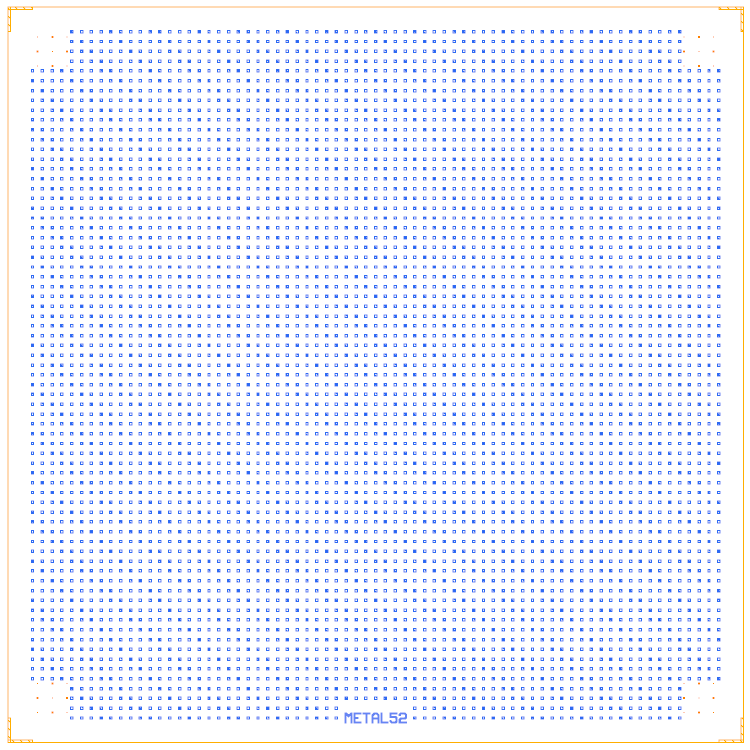

WindowsPath('examples/designs/metal/m52_barends_5q_step_die.png')

In [4]:
d = Designer("m52_barends_5q", box=(0, 0, 7500, 7500),
             chip={"name_chip": "Metal52", "cheese": metal_cheese_rule()}, live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "m52_barends_5q_step_die.png", size=(750, 750), width=375)

## 4 · Pads: the PDK pad rule

The source puts three `LaunchpadWirebond`s on each edge, 2.8 mm from the centre, at −1.5, 0 and +1.5 mm along the
edge: W1–W3 (Q0's Z and XY lines, the feedline input), S1–S3, E1–E3 and N1–N3 (the other control lines and the
feedline output). In the Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from
the die edge**, whatever the source did: `edge="w"` / `"s"` / `"e"` / `"n"` slides each pad perpendicular to its
edge until it is there; its position along the edge is kept, so every line still arrives on the pad's axis and only
its last straight gets longer. The table measures it on the built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_W1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_W2 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_W3 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_E1 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_E2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_E3 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_S1 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP_S2 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP_S3 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP_N1 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| LP_N2 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| LP_N3 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |

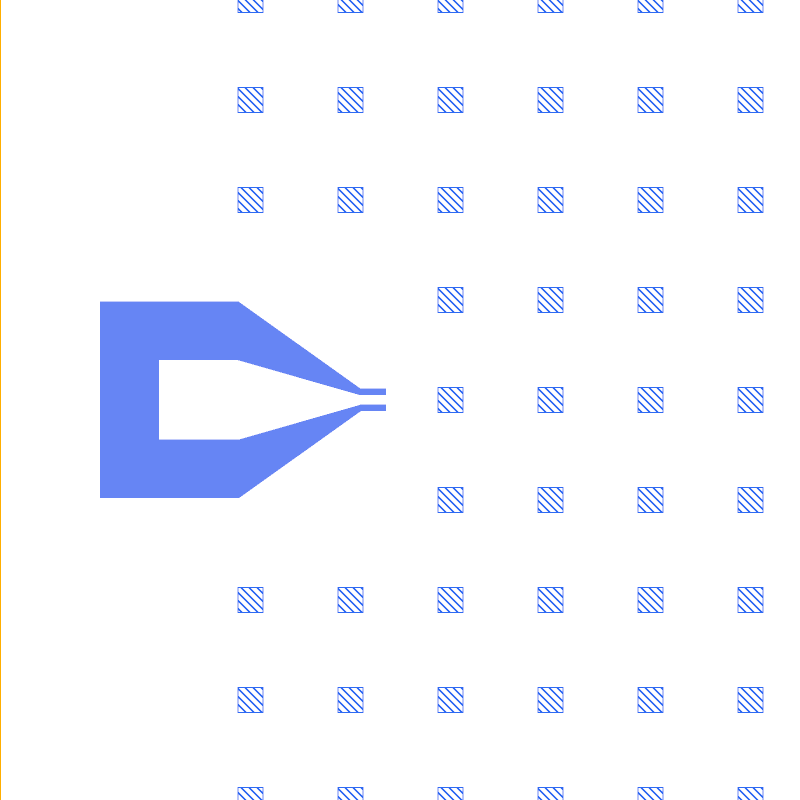

WindowsPath('examples/designs/metal/m52_barends_5q_step_pads.png')

In [5]:
SIDES = {"W": (-2800, None, 0, "w"), "E": (2800, None, 180, "e"), "S": (None, -2800, 90, "s"),
         "N": (None, 2800, 270, "n")}
lp = {}
with d.batch():
    for side, (x, y, r, edge) in SIDES.items():
        for k, c in enumerate((-1500, 0, 1500), 1):
            lp[f"{side}{k}"] = d.add(f"LP_{side}{k}", "metal:LaunchpadWirebond",
                                     at=P(x if x is not None else c, y if y is not None else c), rot=r, edge=edge)
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "LP_W2.tie")
snap(d, OUT / "m52_barends_5q_step_pads.png", box=(0, py - 400, 800, py + 400), size=(800, 800), width=300)

## 5 · Components: the five Xmons, the XY ends, the tees and the Purcell capacitors

**The qubits.** `metal:TransmonCrossFL` is Metal's Xmon with a flux line: a cross of 30 µm wide, 190 µm long arms in
a 50 µm gap, a `readout` claw on its north arm (`claw_length` 40 µm, well short of the 190 µm arm, so the DRC's
`pdk_claw` check is satisfied) and a flux T-line (`fl_options`) at its south arm. The source gives no junction and no
target frequency, so each qubit gets the **PDK SQUID**: `trilayer_junction(..., squid=True)` returns two trilayer
junctions (fingers on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient) whose parallel R_n is the PDK nominal
45 kΩ, so L_J = 6.73 nH at zero flux and C_J = 15 fF. The five qubits stay identical, as in the source.

**XY ends.** Each drive line ends open at a `metal:OpenToGround` 100 µm left of its cross, 180 µm below its centre.

**Tees and Purcell capacitors.** The five `metal:CoupledLineTee`s (200 µm coupled arm, 4 µm space,
`open_termination=False`: the arm's far end is shorted, so the resonator from `second_end` is a λ/4 shorted at the
tee) sit on the feedline at y = +1.5 mm; the two `metal:CapNInterdigital` series capacitors bound the Purcell section.

Each component has named **ports** (Metal's pins); routes connect to them, and the LOM maps each to a circuit node.

SQUID: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q0 ports: ['flux_line', 'readout', 'squid_a', 'squid_b'] | CLT0 ports: ['prime_end', 'prime_start', 'second_end'] | Cap_input: ['north_end', 'south_end']


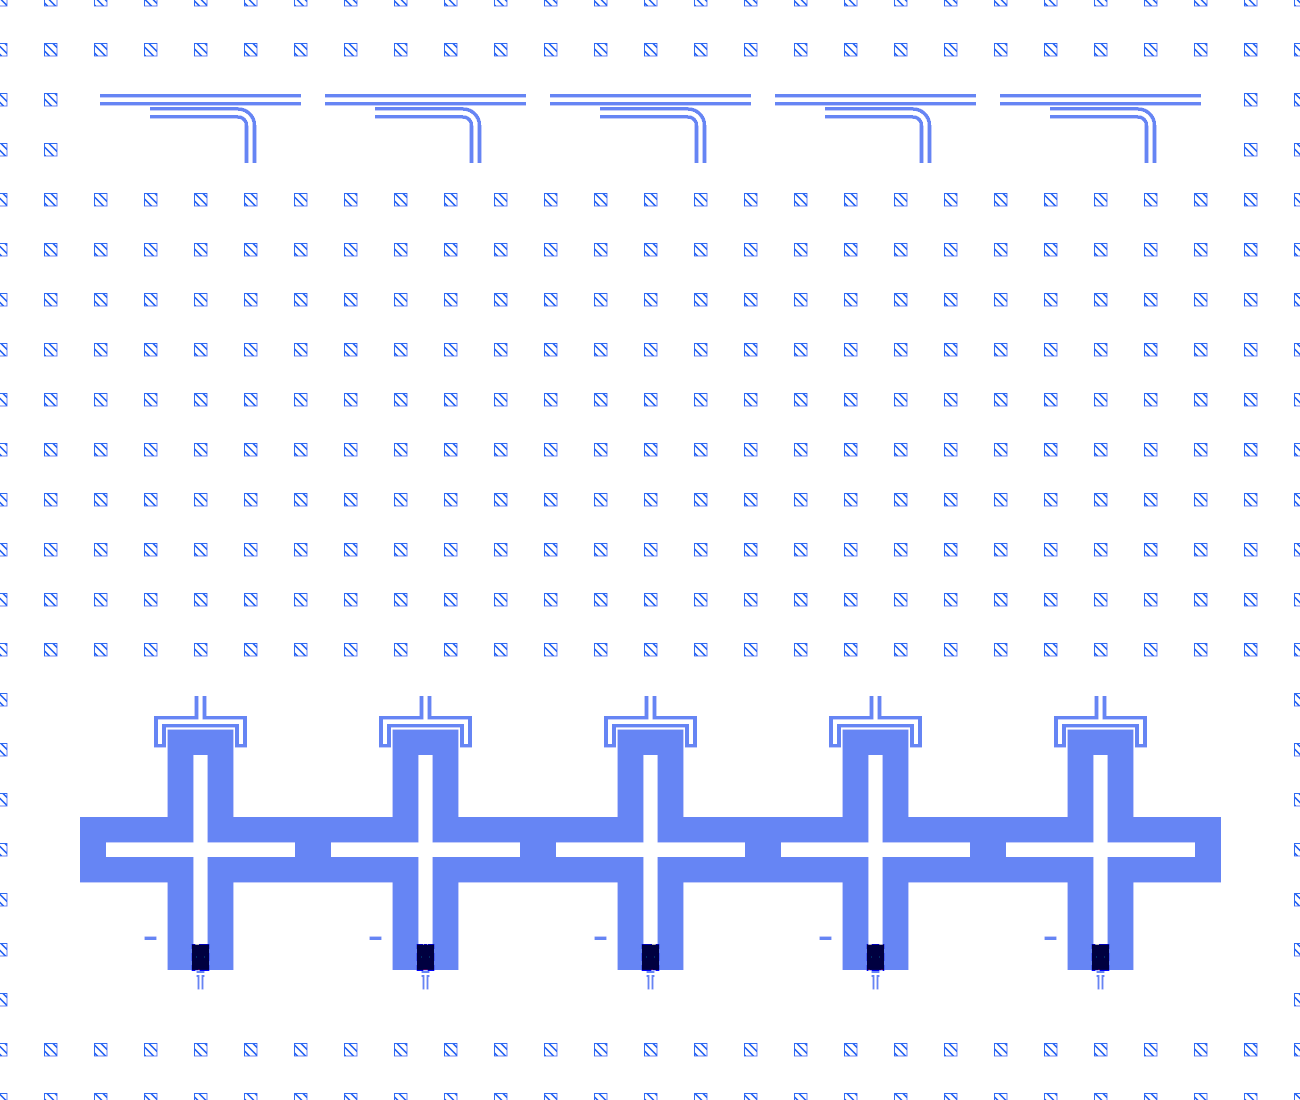

WindowsPath('examples/designs/metal/m52_barends_5q_step_parts.png')

In [6]:
_, JUNCTION = trilayer_junction("metal:TransmonPocket")                    # PDK nominal: R_n 45 kΩ, L_J 6.73 nH
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)  # 45 kΩ in parallel
print("SQUID:", SQ_PARAMS, SQUID)
XS = [(i - 2) * PITCH for i in range(5)]
XMON = dict(cross_width=30, cross_length=190, cross_gap=50, make_fl=True,
            fl_options=dict(t_gap=3, t_inductive_gap=3, t_offset=0, t_top=15, t_width=5),
            connection_pads={"readout": dict(connector_type="0", claw_length=40, ground_spacing=5, claw_width=10,
                                             claw_gap=6, connector_location="90")})
with d.batch():
    q = [d.add(f"Q{i}", "metal:TransmonCrossFL", at=P(x, 0), junction=SQUID, **SQ_PARAMS, **XMON)
         for i, x in enumerate(XS)]
    xy = [d.add(f"XY_pad_{i}", "metal:OpenToGround", at=P(x - 100, -180), rot=90, width=10, gap=6, termination_gap=6)
          for i, x in enumerate(XS)]
    clt = [d.add(f"CLT{i}", "metal:CoupledLineTee", at=P(x, 1500), coupling_length=200, coupling_space=4,
                 open_termination=False) for i, x in enumerate(XS)]
    cap_in = d.add("Cap_input", "metal:CapNInterdigital", at=P(-2400, 1500), rot=270)
    cap_out = d.add("Cap_output", "metal:CapNInterdigital", at=P(-1000, 2100), rot=90)
print("Q0 ports:", sorted(q[0].ports), "| CLT0 ports:", sorted(clt[0].ports), "| Cap_input:", sorted(cap_in.ports))
snap(d, OUT / "m52_barends_5q_step_parts.png", box=P(-1300, -500) + P(1300, 1700), size=(1300, 1100), width=520)

## 6 · Routes: feedline, readout resonators, XY and Z lines

- **Feedline:** launchpad W3 → `Cap_input` → the five tees (the Purcell section between the capacitors) →
  `Cap_output` → launchpad N1. The two long legs follow Metal's `RouteAnchors` corner points (fillets 100 / 20 µm).
- **Readouts:** each claw (open end) → its tee's coupled arm (shorted end) is a λ/4 resonator; `readout_path` lays
  Metal's meander rows as waypoints with the source's length (4410 … 4570 µm, staggered tones).
- **XY and Z lines:** Metal's `RouteFramed` corner points, 10/6 µm CPW, fillet 20 µm; each ends on its edge pad.
- **Neighbour couplings:** the facing cross arms (`d.couple`, a coplanar-strip estimate; no route carries them).
- **Sim groups:** `chain` (a Q3D C-matrix of the five crosses with their XY ends: the direct couplings and the drive
  capacitances) and `readout` (an eigenmode job: qubits, readouts, tees and the Purcell section).

C(Qi ↔ Qi+1) estimate: 3.08 fF (facing arms, 70 µm apart)


route lengths (µm): {'Feed_in_lp': 819.0, 'Feed_in_clt': 1300.0, 'Feed_mid_0': 50.0, 'Feed_mid_1': 50.0, 'Feed_mid_2': 50.0, 'Feed_mid_3': 50.0, 'Feed_out_clt': 6528.3, 'Feed_out_lp': 2285.2, 'ReadoutRes0': 4410.0, 'ReadoutRes1': 4450.0, 'ReadoutRes2': 4490.0, 'ReadoutRes3': 4530.0, 'ReadoutRes4': 4570.0, 'XY_Line_0': 2919.2, 'Z_Line_0': 3677.9, 'XY_Line_1': 4100.7, 'Z_Line_1': 3502.2, 'XY_Line_2': 4850.7, 'Z_Line_2': 5500.6, 'XY_Line_3': 6452.1, 'Z_Line_3': 7250.6, 'XY_Line_4': 7893.5, 'Z_Line_4': 8392.0}
readout run half-widths (Metal 132 … 138 µm): {'ReadoutRes0': 133.74, 'ReadoutRes1': 135.28, 'ReadoutRes2': 136.82, 'ReadoutRes3': 138.36, 'ReadoutRes4': 139.9}


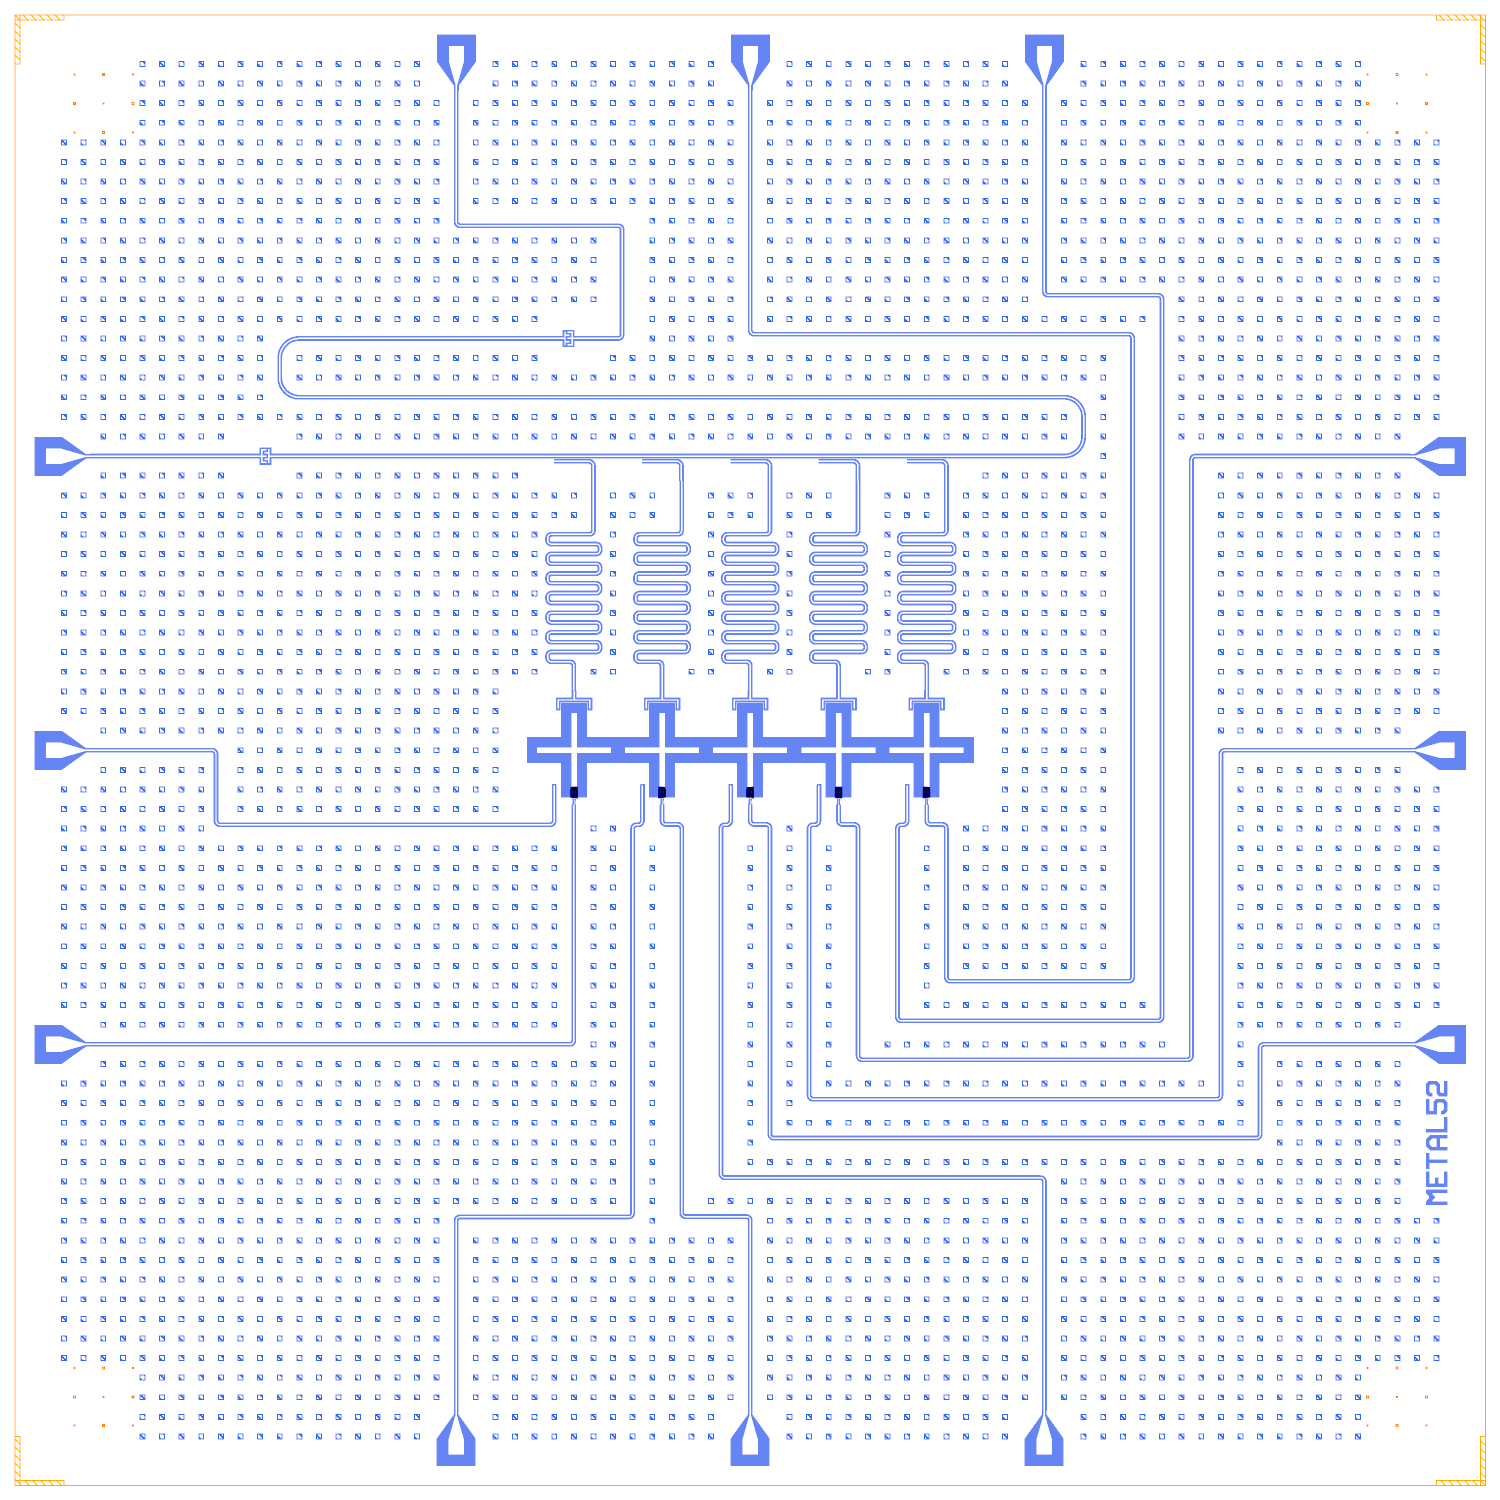

WindowsPath('examples/designs/metal/m52_barends_5q_step_routes.png')

In [7]:
L_READ = [4410, 4450, 4490, 4530, 4570]          # Metal resonator_lengths (staggered tones)
C_QQ = round(est.coplanar_coupling(30, 190, 190, PITCH - 2 * 190, est.substrate_eps(get_pdk())), 2)
print("C(Qi ↔ Qi+1) estimate:", C_QQ, "fF (facing arms, 70 µm apart)")
CTRL = {  # line: (start port, end pad, Metal's RouteFramed corner points)
    "XY_Line_0": (xy[0].open, lp["W2"].tie, [(-1000, -380), (-2725, -380), (-2725, 0)]),
    "Z_Line_0": (q[0].flux_line, lp["W1"].tie, [(-900, -1500)]),
    "XY_Line_1": (xy[1].open, lp["S1"].tie, [(-550, -380), (-600, -380), (-600, -2380), (-1500, -2380)]),
    "Z_Line_1": (q[1].flux_line, lp["S2"].tie, [(-450, -378.5), (-350, -378.5), (-350, -2378.5), (0, -2378.5)]),
    "XY_Line_2": (xy[2].open, lp["S3"].tie, [(-100, -380), (-150, -380), (-150, -2180), (1500, -2180)]),
    "Z_Line_2": (q[2].flux_line, lp["E1"].tie,
                 [(0, -378.5), (100, -378.5), (100, -1978.5), (2600, -1978.5), (2600, -1500)]),
    "XY_Line_3": (xy[3].open, lp["E2"].tie, [(350, -380), (300, -380), (300, -1780), (2400, -1780), (2400, 0)]),
    "Z_Line_3": (q[3].flux_line, lp["E3"].tie,
                 [(450, -378.5), (550, -378.5), (550, -1578.5), (2250, -1578.5), (2250, 1500)]),
    "XY_Line_4": (xy[4].open, lp["N3"].tie,
                  [(800, -380), (750, -380), (750, -1380), (2100, -1380), (2100, 2320), (1500, 2320)]),
    "Z_Line_4": (q[4].flux_line, lp["N2"].tie,
                 [(900, -378.5), (1000, -378.5), (1000, -1178.5), (1950, -1178.5), (1950, 2121.5), (0, 2121.5)]),
}
half_widths = {}
with d.batch():
    # feedline: launchpad → series cap → five tees (the Purcell section) → series cap → launchpad
    d.route("Feed_in_lp", lp["W3"].tie, cap_in.south_end, r=R)
    d.route("Feed_in_clt", cap_in.north_end, clt[0].prime_start, r=R)
    for i in range(4):
        d.route(f"Feed_mid_{i}", clt[i].prime_end, clt[i + 1].prime_start, r=R)
    d.route("Feed_out_clt", clt[4].prime_end, cap_out.north_end, r=100,
            nodes=PP([(1700, 1500), (1700, 1800), (-2400, 1800), (-2400, 2100)]))
    d.route("Feed_out_lp", cap_out.south_end, lp["N1"].tie, r=R, nodes=PP([(-654, 2100), (-654, 2675), (-1500, 2675)]))
    # λ/4 readouts: claw (open) → tee leg (shorted), Metal's meander rows
    for i, x in enumerate(XS):
        pts, half_widths[f"ReadoutRes{i}"] = readout_path(x, L_READ[i])
        d.route(f"ReadoutRes{i}", q[i].readout, clt[i].second_end, r=R, nodes=PP(pts))
    for name, (a, b, pts) in CTRL.items():       # XY (open drive ends) and Z (flux) lines
        d.route(name, a, b, r=R, a=10, b=6, nodes=PP(pts))
    for i in range(4):                           # the facing cross arms: no route carries them
        d.couple(f"Cg_Q{i}_Q{i + 1}", f"Q{i}", f"Q{i + 1}", C_fF=C_QQ, note="facing cross arms, 70 µm (CPS estimate)")
d.sim_group("chain", [f"Q{i}" for i in range(5)] + [f"XY_pad_{i}" for i in range(5)], margin_um=30,
            analyses=["q3d_cmatrix"])
d.sim_group("readout", [f"Q{i}" for i in range(5)] + [f"ReadoutRes{i}" for i in range(5)] + [f"CLT{i}" for i in range(5)]
            + ["Cap_input", "Cap_output", "Feed_in_clt", "Feed_out_clt"] + [f"Feed_mid_{i}" for i in range(4)],
            margin_um=30, analyses=["eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
print("readout run half-widths (Metal 132 … 138 µm):", {k: round(v, 2) for k, v in half_widths.items()})
snap(d, OUT / "m52_barends_5q_step_routes.png", size=(1500, 1500), width=520)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it); it moves nothing when the content is within 50 µm of the centre. Here the twelve pads
sit on all four edges, so the content already spans the die and no shift is needed. Then the design is saved: the
JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "m52_barends_5q.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm
<Designer m52_barends_5q: 29 instances, 23 routes, live=False> → examples\designs\metal\m52_barends_5q.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**; 10 `dangling_port` warnings (`squid_a` / `squid_b` of the five Xmons, the
junction attachment points: the cell draws the SQUID itself, nothing is routed there); 9 `overlap` warnings, by
design (neighbouring Xmon pockets merge at the 450 µm pitch, which is the direct coupling, and each XY
`OpenToGround` sits inside the bounding box of its cross, beside the lower-left arms); **no PDK design warnings**
(the twelve pads are at 100 µm, each PDK SQUID's parallel R_n is the nominal 45 kΩ, the 40 µm claws are short of the
190 µm arms, and the source has no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 19 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 10 | Q0.squid_a is not connected (no route or snap) |
| warning | `overlap` | 9 | Q0 and Q1 overlap |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 75, rows 1000, clearance 25, edge 200 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 5 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit:
- `TransmonCrossFL` → a grounded cross island with its SQUID, a node for the readout claw, the flux line as a
  control (the flux launchpads' ports drop out because the flux T-line shorts to ground);
- each readout claw → `CoupledLineTee` (shorted) is a λ/4 `TLres` (route + tee leg and coupler) with a hanger κ into
  the feedline;
- the four `Cg_Q*` capacitances are the neighbour couplings;
- the XY lines are 50 Ω drive ports ending open (the drive capacitance to the cross is geometric: it is in the
  `chain` C-matrix job).

**Not in the LOM:** the feedline is one node between the two series capacitors, so its ≈ 10 mm Purcell section
(λ/2 near the readouts) is not a resonator here; the eigenmode job `readout` contains it.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q2.", "CLT2."))})

**19 nodes · 47 branches · 5 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `XY_pad_0.end` | `LP_W2.pad`, `XY_pad_0.end` |
| `Cap_input.b` | `LP_W3.pad`, `Cap_input.south_end` |
| `XY_pad_3.end` | `LP_E2.pad`, `XY_pad_3.end` |
| `XY_pad_1.end` | `LP_S1.pad`, `XY_pad_1.end` |
| `XY_pad_2.end` | `LP_S3.pad`, `XY_pad_2.end` |
| `Cap_output.b` | `LP_N1.pad`, `Cap_output.south_end` |
| `XY_pad_4.end` | `LP_N3.pad`, `XY_pad_4.end` |
| `Q0` | `Q0.island` |
| `Q0.readout` | `Q0.readout`, `CLT0.second_end` |
| `Q1` | `Q1.island` |
| `Q1.readout` | `Q1.readout`, `CLT1.second_end` |
| `Q2` | `Q2.island` |
| `Q2.readout` | `Q2.readout`, `CLT2.second_end` |
| `Q3` | `Q3.island` |
| `Q3.readout` | `Q3.readout`, `CLT3.second_end` |
| `Q4` | `Q4.island` |
| `Q4.readout` | `Q4.readout`, `CLT4.second_end` |
| `CLT0.prime` | `CLT0.prime`, `CLT1.prime`, `CLT2.prime`, `CLT3.prime`, `CLT4.prime`, `Cap_input.north_end`, `Cap_output.north_end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_LP_W2` | R | `XY_pad_0.end` – `gnd` | 50 Ω |
| `Port_LP_W3` | R | `Cap_input.b` – `gnd` | 50 Ω |
| `Port_LP_E2` | R | `XY_pad_3.end` – `gnd` | 50 Ω |
| `Port_LP_S1` | R | `XY_pad_1.end` – `gnd` | 50 Ω |
| `Port_LP_S3` | R | `XY_pad_2.end` – `gnd` | 50 Ω |
| `Port_LP_N1` | R | `Cap_output.b` – `gnd` | 50 Ω |
| `Port_LP_N3` | R | `XY_pad_4.end` – `gnd` | 50 Ω |
| `C_Q0` | C | `Q0` – `gnd` | 70.3 fF |
| `J_Q0` | SQUID | `Q0` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q0_readout` | C | `Q0` – `Q0.readout` | 1.7 fF |
| `Cc_Q0_readout` | C | `Q0.readout` – `gnd` | 43.1 fF |
| `C_Q1` | C | `Q1` – `gnd` | 70.3 fF |
| `J_Q1` | SQUID | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_readout` | C | `Q1` – `Q1.readout` | 1.7 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 43.1 fF |
| `C_Q2` | C | `Q2` – `gnd` | 70.3 fF |
| `J_Q2` | SQUID | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_readout` | C | `Q2` – `Q2.readout` | 1.7 fF |
| `Cc_Q2_readout` | C | `Q2.readout` – `gnd` | 43.1 fF |
| `C_Q3` | C | `Q3` – `gnd` | 70.3 fF |
| `J_Q3` | SQUID | `Q3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_readout` | C | `Q3` – `Q3.readout` | 1.7 fF |
| `Cc_Q3_readout` | C | `Q3.readout` – `gnd` | 43.1 fF |
| `C_Q4` | C | `Q4` – `gnd` | 70.3 fF |
| `J_Q4` | SQUID | `Q4` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_readout` | C | `Q4` – `Q4.readout` | 1.7 fF |
| `Cc_Q4_readout` | C | `Q4.readout` – `gnd` | 43.1 fF |
| `C_Cap_input` | C | `CLT0.prime` – `Cap_input.b` | 5.26 fF |
| `C_Cap_input_a` | C | `CLT0.prime` – `gnd` | 19 fF |
| `C_Cap_input_b` | C | `Cap_input.b` – `gnd` | 19 fF |
| `C_Cap_output` | C | `CLT0.prime` – `Cap_output.b` | 5.26 fF |
| `C_Cap_output_a` | C | `CLT0.prime` – `gnd` | 19 fF |
| `C_Cap_output_b` | C | `Cap_output.b` – `gnd` | 19 fF |
| `C_Cg_Q0_Q1` | C | `Q0` – `Q1` | 3.08 fF |
| `C_Cg_Q1_Q2` | C | `Q1` – `Q2` | 3.08 fF |
| `C_Cg_Q2_Q3` | C | `Q2` – `Q3` | 3.08 fF |
| `C_Cg_Q3_Q4` | C | `Q3` – `Q4` | 3.08 fF |
| `CLT0` | TLres | `Q0.readout` – `gnd` | lambda/4, 4710 µm, 6.690 GHz |
| `K_CLT0` | HANGER | `Q0.readout` – `CLT0.prime` | κ 0.124 MHz (L 200 µm) |
| `CLT1` | TLres | `Q1.readout` – `gnd` | lambda/4, 4750 µm, 6.633 GHz |
| `K_CLT1` | HANGER | `Q1.readout` – `CLT0.prime` | κ 0.121 MHz (L 200 µm) |
| `CLT2` | TLres | `Q2.readout` – `gnd` | lambda/4, 4790 µm, 6.578 GHz |
| `K_CLT2` | HANGER | `Q2.readout` – `CLT0.prime` | κ 0.118 MHz (L 200 µm) |
| `CLT3` | TLres | `Q3.readout` – `gnd` | lambda/4, 4830 µm, 6.524 GHz |
| `K_CLT3` | HANGER | `Q3.readout` – `CLT0.prime` | κ 0.115 MHz (L 200 µm) |
| `CLT4` | TLres | `Q4.readout` – `gnd` | lambda/4, 4870 µm, 6.470 GHz |
| `K_CLT4` | HANGER | `Q4.readout` – `CLT0.prime` | κ 0.112 MHz (L 200 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `Z_Line_0` | flux_bias | `J_Q0` | `Z_Line_0` | 3678 |
| `Z_Line_1` | flux_bias | `J_Q1` | `Z_Line_1` | 3502 |
| `Z_Line_2` | flux_bias | `J_Q2` | `Z_Line_2` | 5501 |
| `Z_Line_3` | flux_bias | `J_Q3` | `Z_Line_3` | 7251 |
| `Z_Line_4` | flux_bias | `J_Q4` | `Z_Line_4` | 8392 |

**Unconnected ports:** none

**Builder notes:**

- CLT0: coupled-line κ uses the hanger k for a 4 µm gap (rough)
- CLT1: coupled-line κ uses the hanger k for a 4 µm gap (rough)
- CLT2: coupled-line κ uses the hanger k for a 4 µm gap (rough)
- CLT3: coupled-line κ uses the hanger k for a 4 µm gap (rough)
- CLT4: coupled-line κ uses the hanger k for a 4 µm gap (rough)
- Port_LP_W1: both ends on gnd after merging conductors (dropped)
- Port_LP_E1: both ends on gnd after merging conductors (dropped)
- Port_LP_E3: both ends on gnd after merging conductors (dropped)
- Port_LP_S2: both ends on gnd after merging conductors (dropped)
- Port_LP_N2: both ends on gnd after merging conductors (dropped)

{'Q2.squid_a': 'Q2', 'Q2.squid_b': 'gnd', 'Q2.readout': 'Q2.readout', 'Q2.flux_line': 'control:flux', 'CLT2.prime_start': 'CLT0.prime', 'CLT2.prime_end': 'CLT0.prime', 'CLT2.second_end': 'Q2.readout'}


## 10 · LOM simulation

QuCat solves the circuit's normal modes (frequency, κ through the 50 Ω ports, anharmonicity); QuTiP diagonalises the
dressed Hamiltonian for f_q, α, f_r and χ. First each qubit with its readout and tee (the feedline is outside the
selection: with the whole feedline in, QuCat does not finish in reasonable time), then the five-qubit chain with
the four direct couplings. The source states no targets; the PDK band is 4–8 GHz.

What the tables show (this run):
- the five qubits at 6.35–6.36 GHz, α −266 … −277 MHz (Q4 −212 MHz: its readout sits closest), right on top of the
  λ/4 readouts at 6.09–6.27 GHz (staggered by ≈ 47 MHz, as the source intends): with the PDK SQUIDs at zero flux the
  qubits and readouts collide, so χ is large and of either sign (Q4 −31 MHz, the others +23 … +30 MHz). The source's
  frequency plan needs the Z lines (or another junction, step 13) to detune them; this is flagged, not retuned;
- **κ is 0 here, not a result:** the tee's feed side is the lumped feedline node of step 9, which has no load when
  the feedline is outside the selection; the builder's hanger estimate into a matched line is in the netlist
  (`K_CLT*`), and the Purcell filter's effect needs the eigenmode job;
- the qubits are identical, so the chain's five modes are delocalised (hybridised, 6.19–6.58 GHz) and a per-pair ZZ
  is not defined ("–" in the ZZ table). Their spread comes from the coplanar-strip arm-to-arm estimate, which ignores
  the screening by the pocket ground beside the arms (an upper estimate; the Q3D `chain` job gives the real value).

In [11]:
READ = {f"Q{i}+R{i}": [f"Q{i}", f"ReadoutRes{i}", f"CLT{i}"] for i in range(5)}
results = simulate_groups(d, READ)
display(Markdown(groups_md(results)))
chain = simulate_groups(d, {"chain": [f"Q{i}" for i in range(5)]}, max_modes=5)
display(Markdown("**Q0–Q4 chain, QuCat normal modes:**\n\n" + modes_md(chain["chain"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(chain)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0+R0 | Q0 | 6.3569 | -276.8 | CLT0 | 6.2749 | 0 | 28 |
| Q1+R1 | Q1 | 6.3519 | -272.4 | CLT1 | 6.23 | 0 | 23.3 |
| Q2+R2 | Q2 | 6.3497 | -265.7 | CLT2 | 6.1832 | 0 | 23.9 |
| Q3+R3 | Q3 | 6.3484 | -272.8 | CLT3 | 6.1361 | 0 | 30.2 |
| Q4+R4 | Q4 | 6.3477 | -211.5 | CLT4 | 6.0893 | 0 | -31.3 |

**Q0–Q4 chain, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 6.1927 | 0 | 59.2 | J_Q2 0.40, J_Q1 0.26, J_Q3 0.26 |
| Q1 | qubit | 6.2923 | 0 | 61.2 | J_Q3 0.36, J_Q1 0.36, J_Q4 0.14 |
| Q0 | qubit | 6.4223 | 0 | 63.7 | J_Q2 0.40, J_Q0 0.26, J_Q4 0.26 |
| Q4 | qubit | 6.5336 | 0 | 66.0 | J_Q4 0.36, J_Q0 0.36, J_Q3 0.14 |
| Q3 | qubit | 6.5777 | 0 | 44.6 | J_Q0 0.20, J_Q1 0.20, J_Q2 0.20 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| chain | Q1-Q2 | – | yes | yes |
| chain | Q0-Q2 | – | no | yes |
| chain | Q2-Q4 | – | no | yes |
| chain | Q2-Q3 | – | yes | yes |
| chain | Q0-Q1 | – | yes | yes |
| chain | Q1-Q4 | – | no | yes |
| chain | Q1-Q3 | – | no | yes |
| chain | Q0-Q4 | – | no | yes |
| chain | Q0-Q3 | – | no | yes |
| chain | Q3-Q4 | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs: a **Q3D C-matrix** for the qubit chain with the XY ends (the direct couplings and the drive capacitances;
the box cuts each readout, XY and Z line once: they become ports), and an **eigenmode / EPR** job for the qubits,
readouts, tees and the Purcell section (lines leaving the box end in 50 Ω, so the mode Q gives κ through the filter;
`Z_Line_4` passes through the box top).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN, ["chain"])
jobs_eig = export_sims(DESIGN, ["readout"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| chain | `build/jobs/m52_barends_5q_chain_q3d_cmatrix` | 1 · junction · `Q0.junction`<br>2 · junction · `Q1.junction`<br>3 · junction · `Q2.junction`<br>4 · junction · `Q3.junction`<br>5 · junction · `Q4.junction`<br>6 · edge · `ReadoutRes0`<br>7 · edge · `ReadoutRes1`<br>8 · edge · `ReadoutRes2`<br>9 · edge · `ReadoutRes3`<br>10 · edge · `ReadoutRes4`<br>11 · edge · `XY_Line_0`<br>12 · edge · `XY_Line_1`<br>13 · edge · `XY_Line_2`<br>14 · edge · `XY_Line_3`<br>15 · edge · `XY_Line_4`<br>16 · edge · `Z_Line_0`<br>17 · edge · `Z_Line_1`<br>18 · edge · `Z_Line_2`<br>19 · edge · `Z_Line_3`<br>20 · edge · `Z_Line_4` | `Q0.island`, `Q1.island`, `Q2.island`, `Q3.island`, `Q4.island`, `ReadoutRes0`, `ReadoutRes1`, `ReadoutRes2`, `ReadoutRes3`, `ReadoutRes4`, `XY_Line_0`, `XY_Line_1`, `XY_Line_2`, `XY_Line_3`, `XY_Line_4` |
| readout | `build/jobs/m52_barends_5q_readout_eigenmode_epr` | 1 · junction · `Q0.junction`<br>2 · junction · `Q1.junction`<br>3 · junction · `Q2.junction`<br>4 · junction · `Q3.junction`<br>5 · junction · `Q4.junction`<br>6 · edge_lumped · `Feed_in_lp`<br>7 · edge_lumped · `Feed_out_lp`<br>8 · edge_lumped · `XY_Line_0`<br>9 · edge_lumped · `XY_Line_1`<br>10 · edge_lumped · `XY_Line_2`<br>11 · edge_lumped · `XY_Line_3`<br>12 · edge_lumped · `XY_Line_4`<br>13 · edge_lumped · `Z_Line_0`<br>14 · edge_lumped · `Z_Line_1`<br>15 · edge_lumped · `Z_Line_2`<br>16 · edge_lumped · `Z_Line_3`<br>17 · edge_lumped · `Z_Line_4`<br>18 · edge_lumped · `Z_Line_4`<br>19 · edge_lumped · `Z_Line_4` | `Q0.island`, `Q1.island`, `Q2.island`, `Q3.island`, `Q4.island`, `Feed_in_lp`, `Feed_out_lp`, `XY_Line_0`, `XY_Line_1`, `XY_Line_2`, `XY_Line_3`, `XY_Line_4`, `Z_Line_0`, `Z_Line_1`, `Z_Line_2`, `Z_Line_3`, `Z_Line_4`, `Z_Line_4#2`, `Z_Line_4#3`, `CLT0.prime` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ["chain", "readout"], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates. For this chip the
`chain` C-matrix replaces the assumed arm-to-arm `Cg_Q*` and gives the XY drive capacitances.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                              **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for chain · q3d, readout · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property, rebuild, re-run the LOM and compare. Here Q2's SQUID goes from the PDK nominal (L_J 6.73 nH, R_n 45 kΩ) to the top of
the PDK window (R_n ≈ 50 kΩ, L_J 7.32 nH as drawn): the most the PDK allows to move a qubit down without leaving the
R_n window. f_q drops by ≈ 240 MHz (6.35 → 6.11 GHz), below its readout (6.20 GHz), so χ changes sign
(+24 → −14 MHz) and |α| comes down as the qubit–readout hybridisation changes. Detuning all five well below their
readouts needs the Z lines, as in the source.

In [15]:
pdk_j = get_pdk().junction
LJ_50K = round(SQUID["Lj_nH"] * pdk_j.rn_target_kohm[1] / pdk_j.rn_nominal_kohm, 2)   # L_J ∝ R_n: R_n 50 kΩ
SQ50_PARAMS, SQUID_50K = trilayer_junction("metal:TransmonCrossFL", lj_nH=LJ_50K, squid=True)
print(f"Q2 SQUID: L_J {SQUID['Lj_nH']} → {SQUID_50K['Lj_nH']} nH (R_n 45 → ≈ 50 kΩ, the top of the PDK window)")
d2 = design_copy(DESIGN)
d2["Q2"].set(junction=SQUID_50K, **SQ50_PARAMS)
display(Markdown(params_delta_md({"Q2+R2": results["Q2+R2"]}, simulate_groups(d2, {"Q2+R2": READ["Q2+R2"]}))))

Q2 SQUID: L_J 6.7344 → 7.32 nH (R_n 45 → ≈ 50 kΩ, the top of the PDK window)


| parameter | before | after | Δ |
|---|---|---|---|
| `Q2+R2: CLT2.f_GHz` | 6.1832 | 6.1983 | +0.01516 |
| `Q2+R2: CLT2.kappa_MHz` | 0 | 0 | +0 |
| `Q2+R2: CLT2.chi_MHz` | 23.859 | -13.882 | -37.74 |
| `Q2+R2: Q2.f_q_GHz` | 6.3497 | 6.1063 | -0.2434 |
| `Q2+R2: Q2.alpha_MHz` | -265.71 | -232.43 | +33.28 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** Example 52 ends by exporting its chip with Metal's `QGDSRenderer`
(`gds_renderer.export_to_gds(...)`; "the renderer logs notes on cheesing"), with the cheese at its defaults: on for
the main layer (`cheese.view_in_file = {main: {1: True}}`), `cheese_0_x/y` 25 µm squares every `delta_x/y` 100 µm,
none within `edge_nocheese` 200 µm of the chip edge and `no_cheese.buffer` 25 µm clear of every etched shape. So the
original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule
as its `cheese` parameter (step 3: `metal_cheese_rule()` = `{size, gap, rows, clearance, edge}`), so the build draws
it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0
keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few
µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask`
keep it (`cheese source: build`, no PDK band added). (Before 2026-11-04 the cheese was drawn but KQC's layer
properties hid `ground grid` 132/1, the "no cheese in Barends 52" seen in KLayout; snapshots now use
`live.snapshot.layer_props_path()`, which shows it. Load that file in KLayout, File → Load Layer Properties, to see
it in the GUI.)

Command-line equivalents:
- `qcc build examples/designs/metal/m52_barends_5q.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/m52_barends_5q.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/m52_barends_5q.json -g chain -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\m52_barends_5q.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 3761 |
| 2/0 | JJ_STRAIGHT | 5 |
| 3/0 | M3 | 3734 |
| 4/0 | JJ_BENT | 5 |
| 50/0 | HSQ | 20 |
| 51/0 | SPACER_1 | 20 |
| 52/0 | SPACER_2 | 20 |
| 53/0 | SPACER_3 | 20 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 3732 holes on the mask.

→ `build/m52_barends_5q_fab.oas`

## 15 · Snapshots

The full chip (compare the source's last figure: the same components, pins and route paths, the pads now at the die
edge, Metal's cheese over the free ground); the five Xmons with their merged pockets; Q2's cross with its readout
claw, XY end and flux T-line; Q2's trilayer SQUID; the Q0 tee on the feedline; the **fab mask** round Q2 (1/0 etch
with the Metal cheese, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on
1000/0, alignment grid on 1001/0). Positions are read from the design.

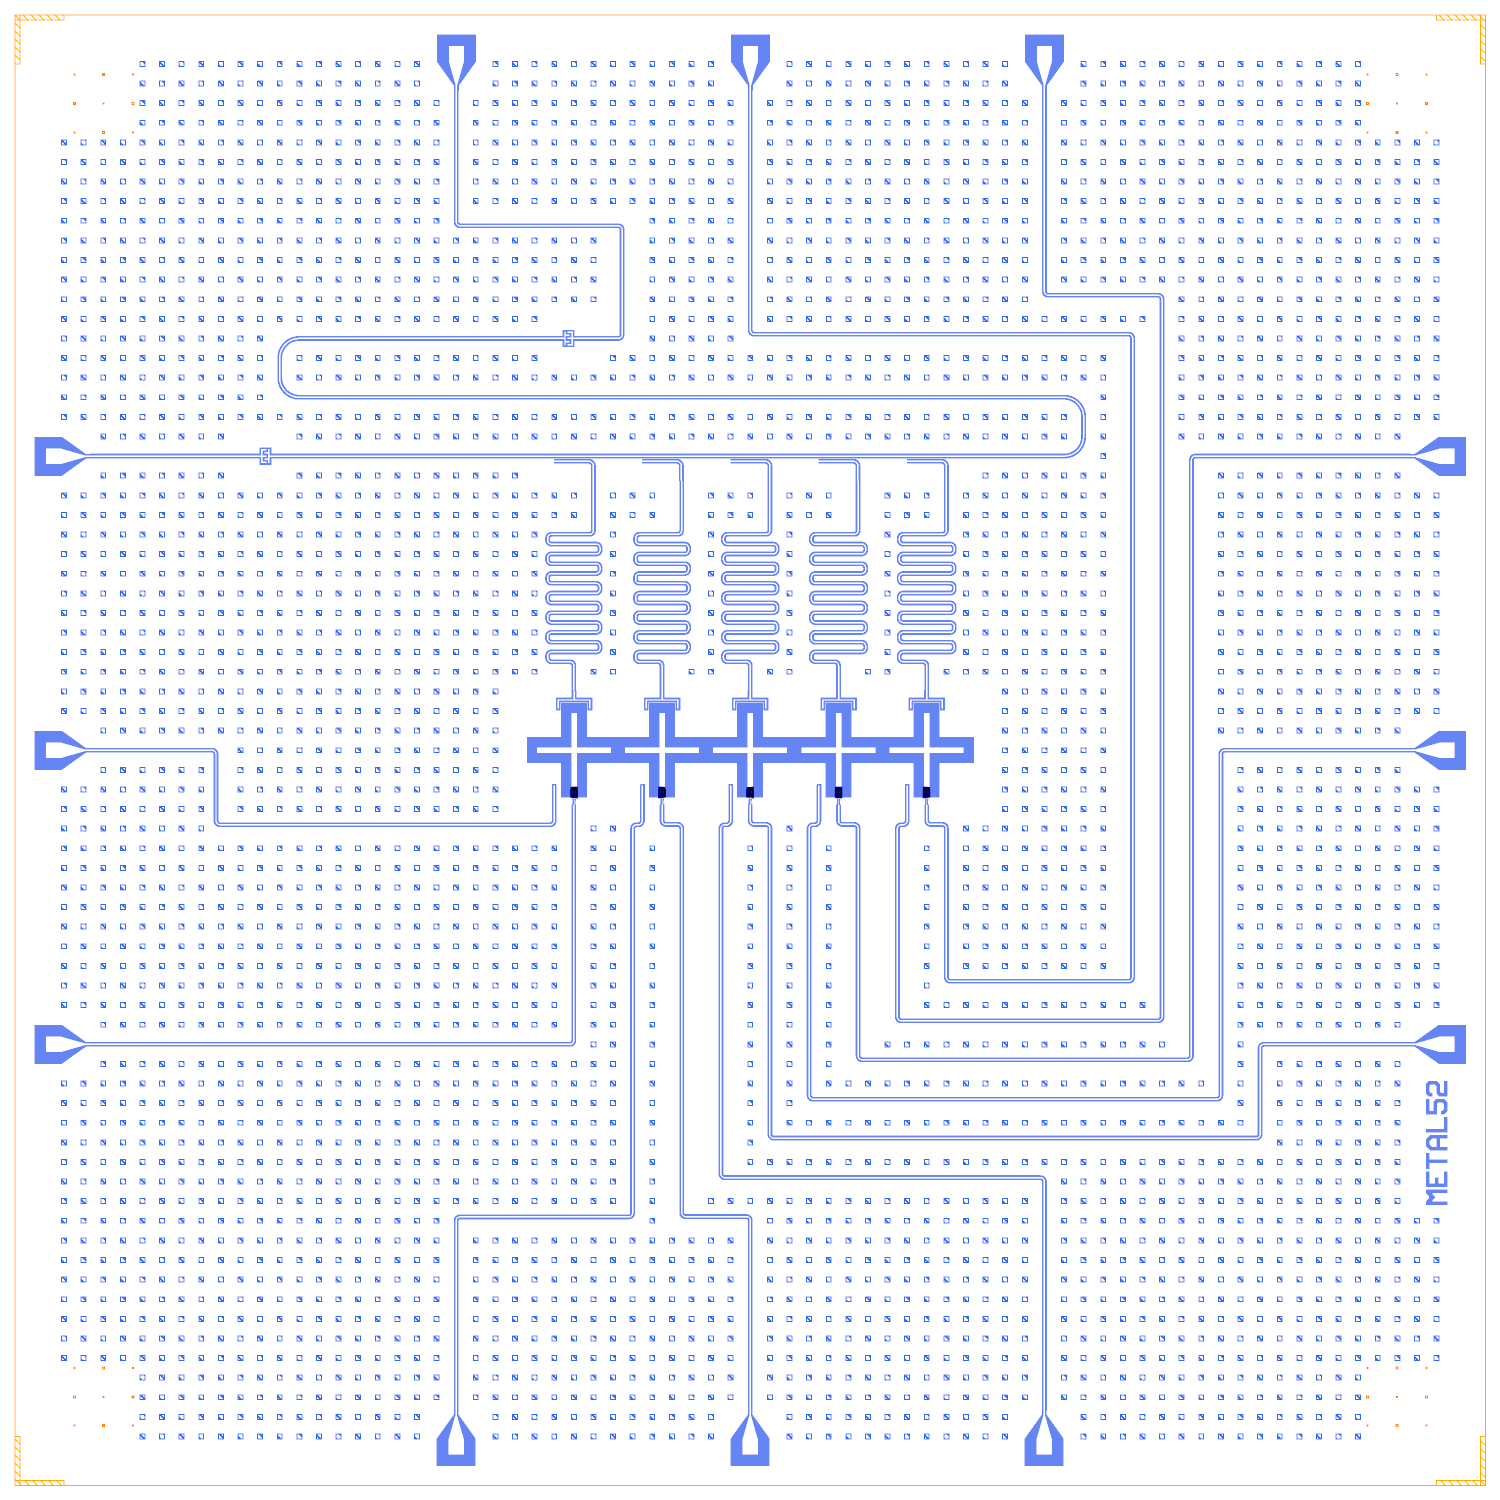

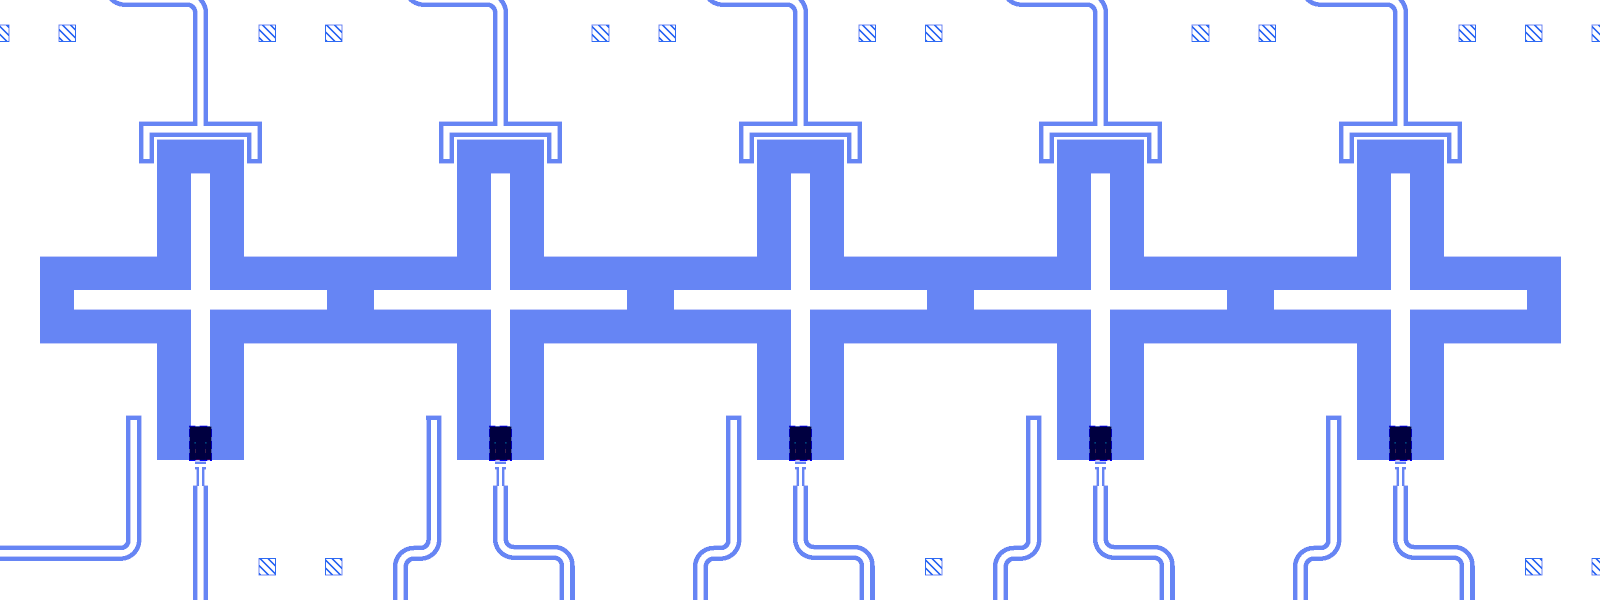

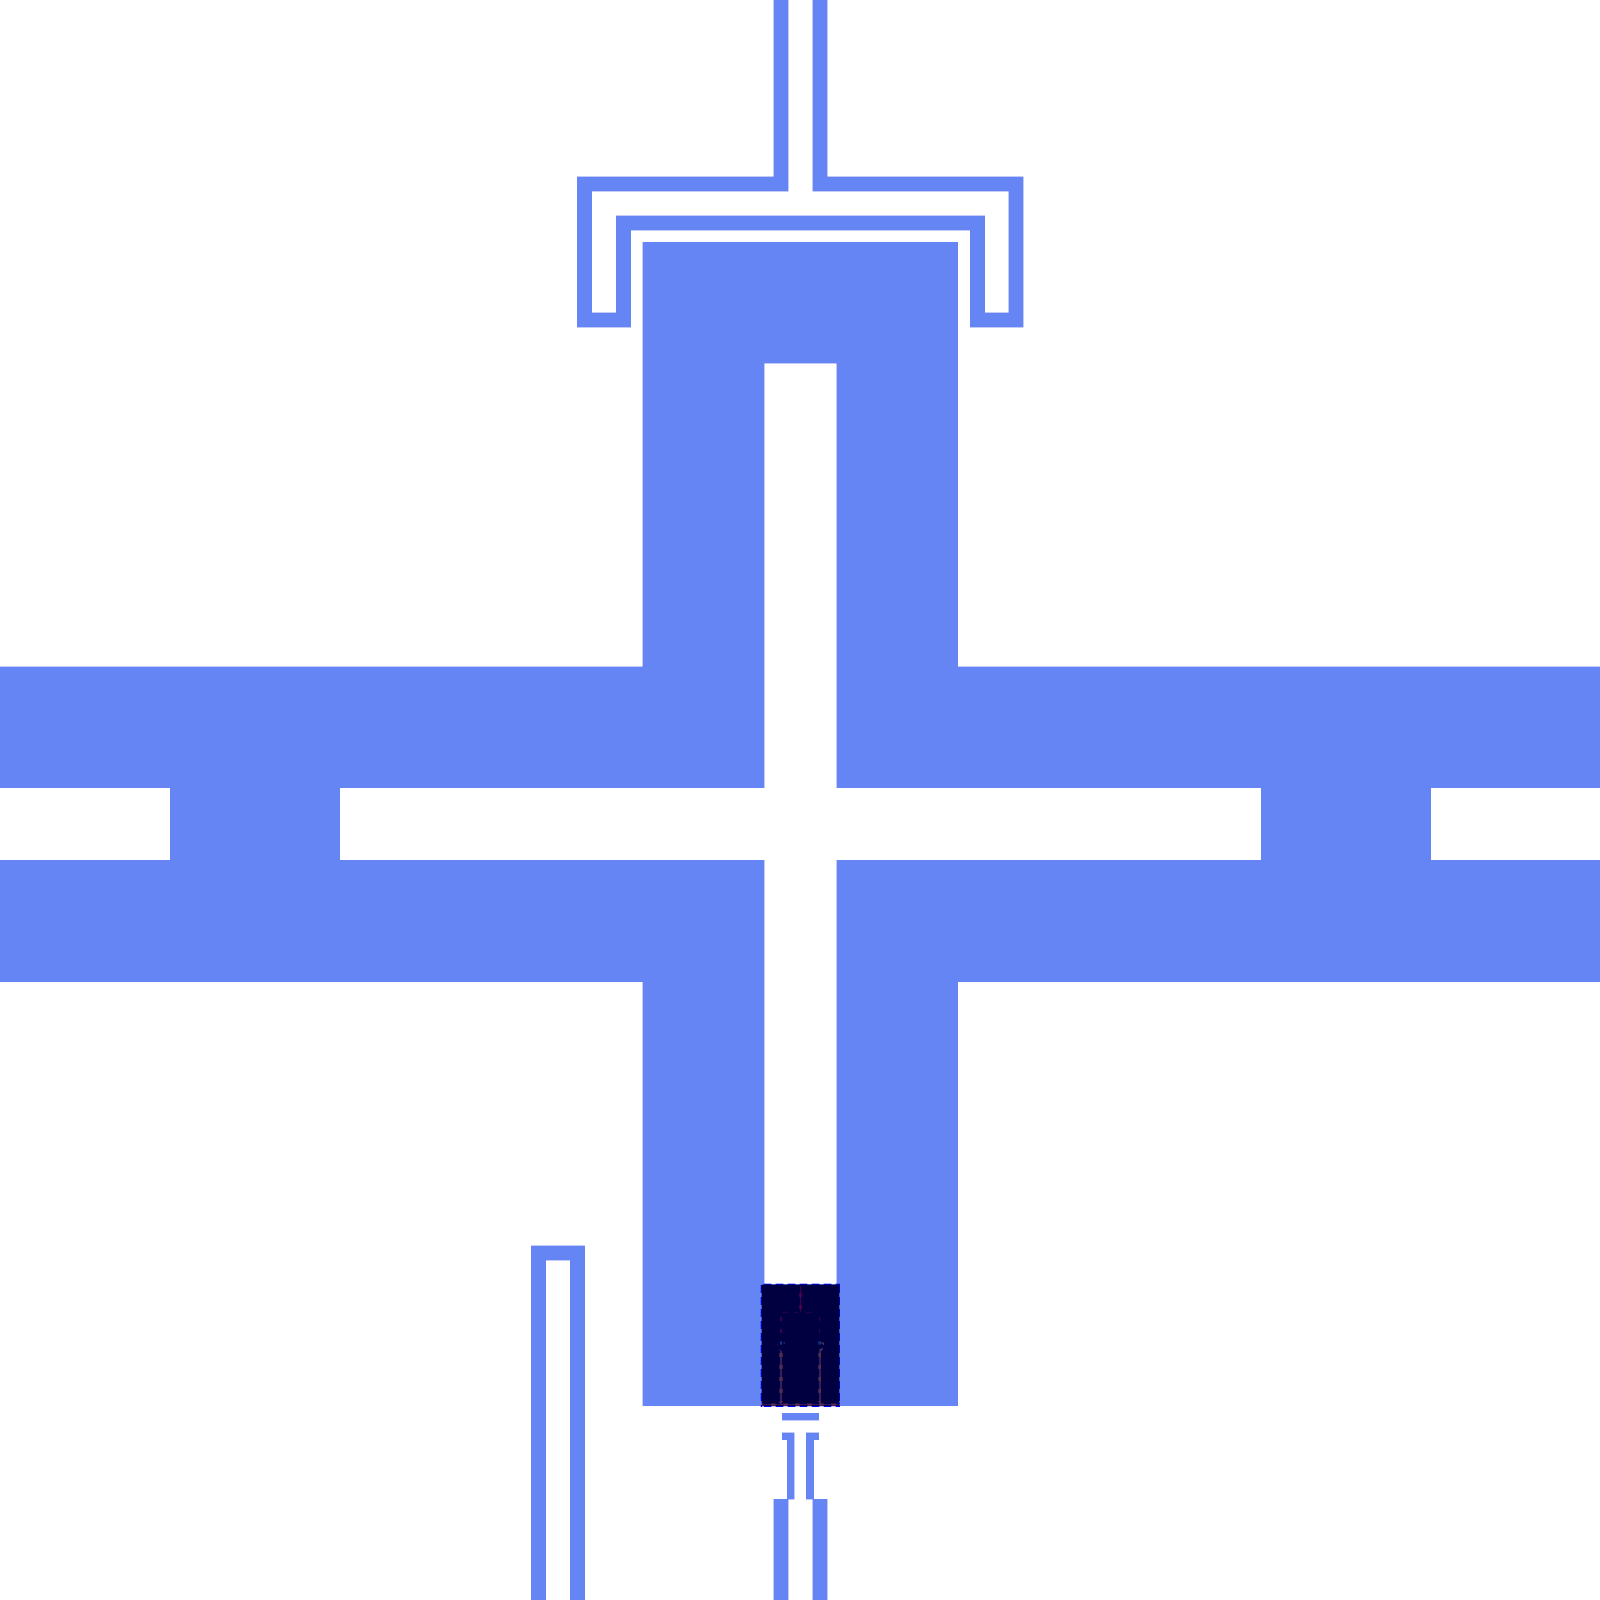

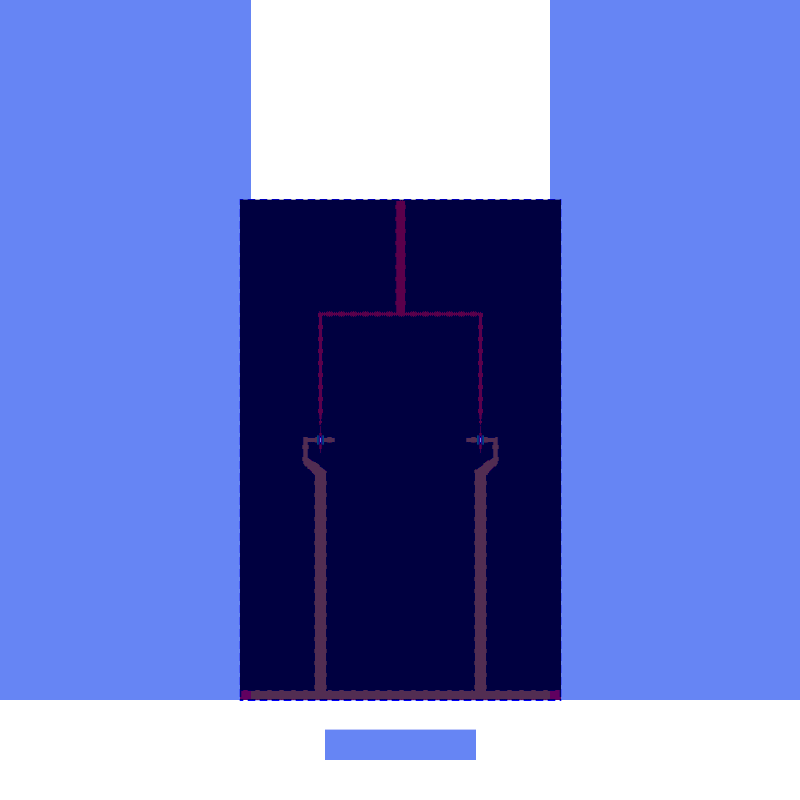

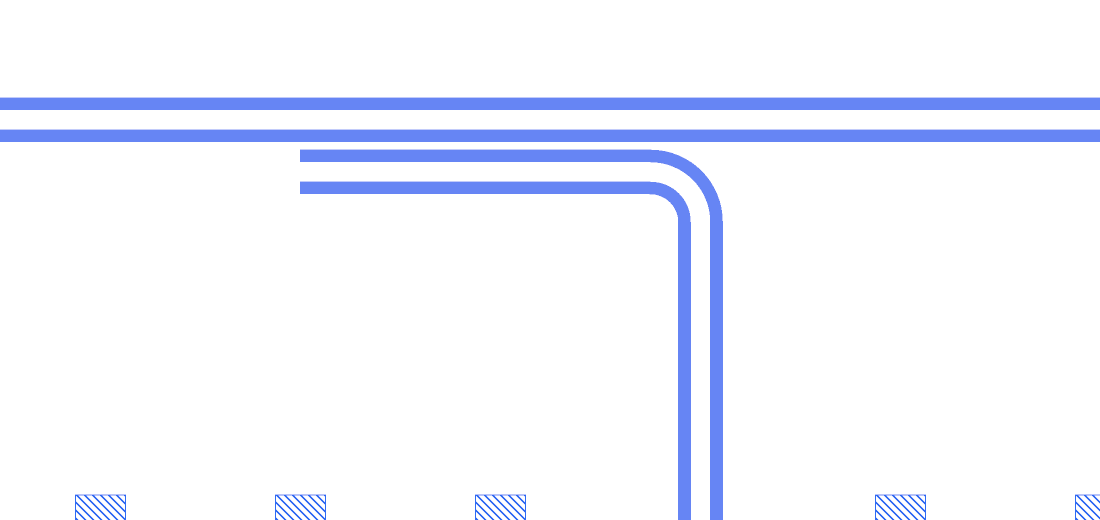

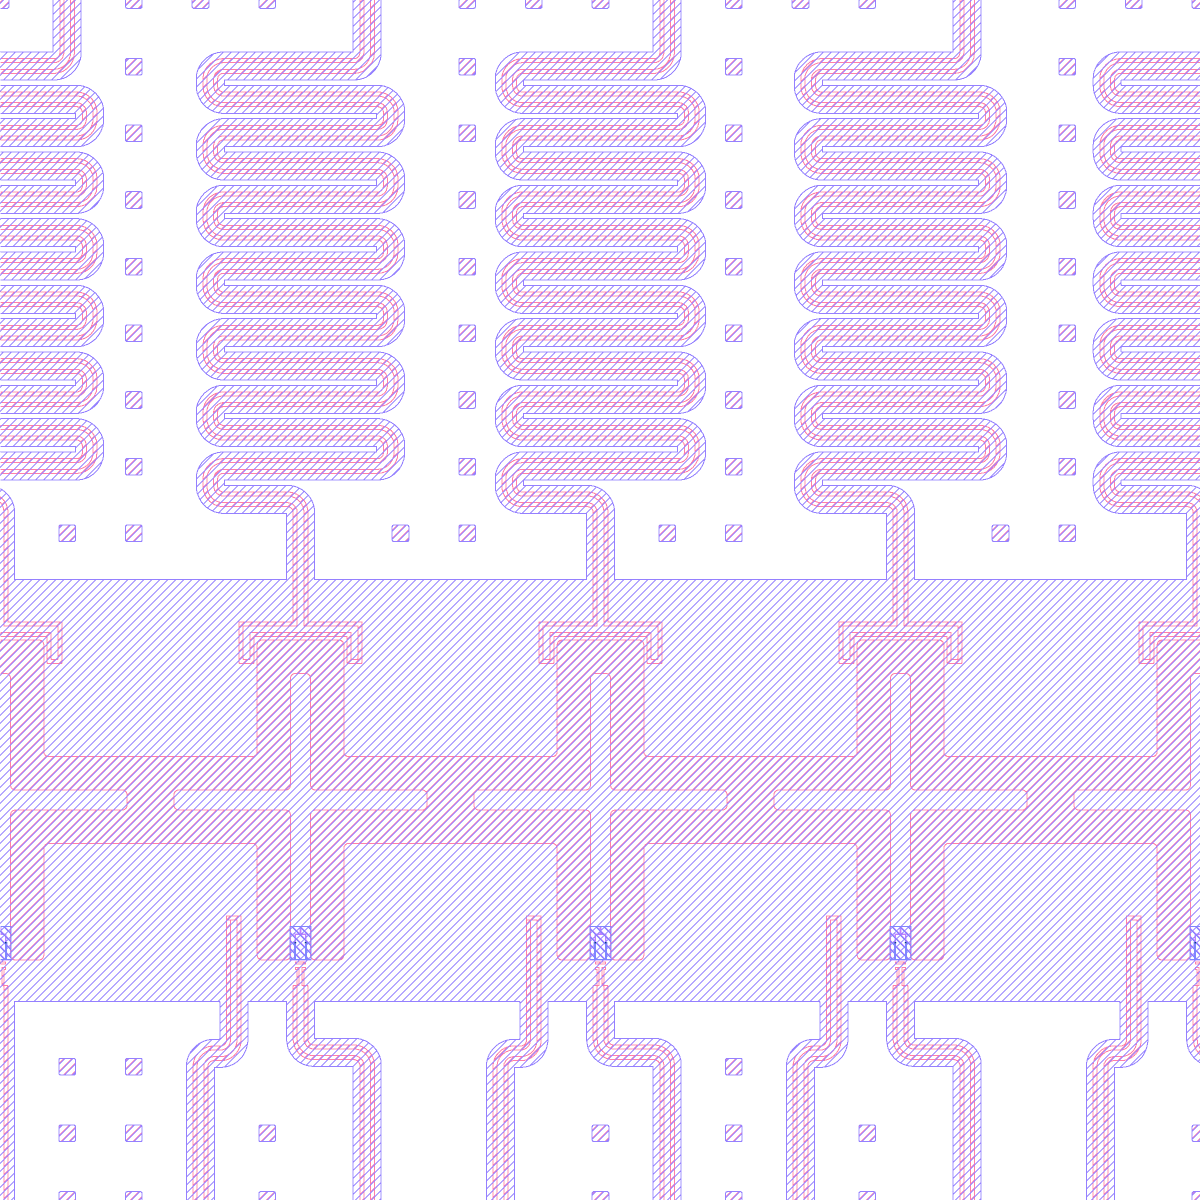

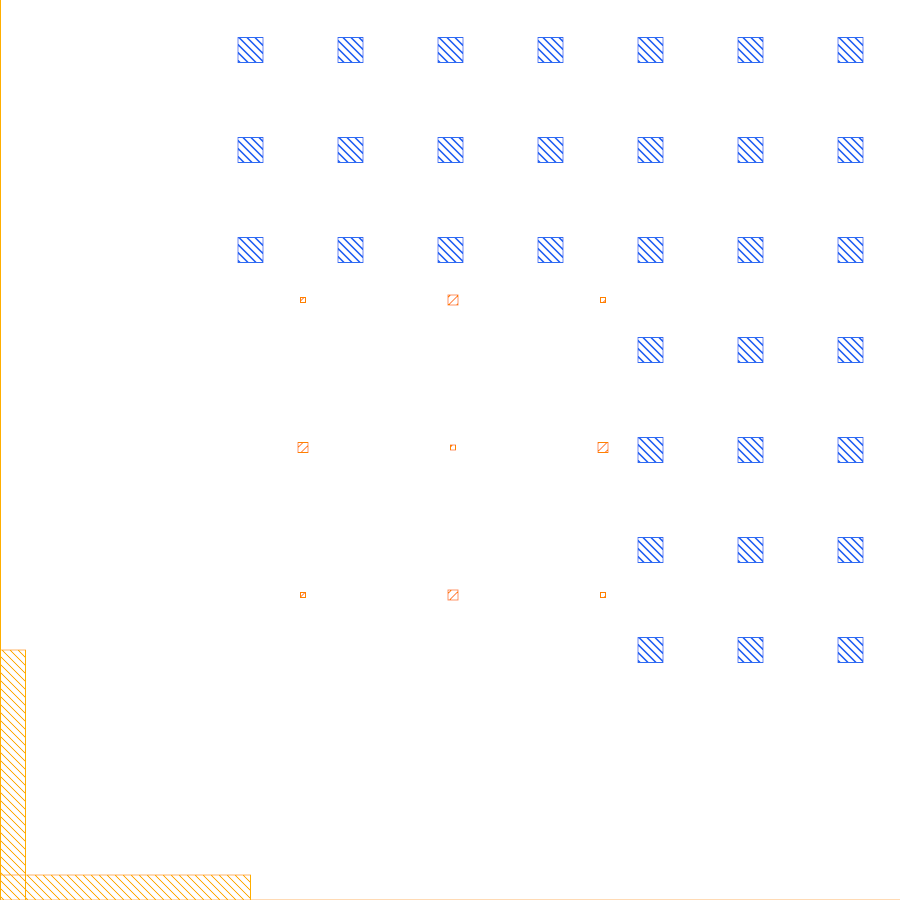

In [17]:
QX, QY = d.data["instances"]["Q2"]["place"]["at"]
TX, TY = d.data["instances"]["CLT0"]["place"]["at"]
show_snapshot(d, OUT / "m52_barends_5q.png", size=(1500, 1500))
show_snapshot(d, OUT / "m52_barends_5q_chain.png", box=(QX - 1200, QY - 450, QX + 1200, QY + 450), size=(1600, 600),
              width=640)
show_snapshot(d, OUT / "m52_barends_5q_q2.png", box=(QX - 280, QY - 320, QX + 280, QY + 340), width=400)
show_snapshot(d, OUT / "m52_barends_5q_jj.png", box=(QX - 40, QY - 250, QX + 40, QY - 170), size=(800, 800),
              width=300)
show_snapshot(d, OUT / "m52_barends_5q_tee.png", box=(TX - 250, TY - 200, TX + 300, TY + 60), size=(1100, 520),
              width=440)
snap_file(Path("build") / "m52_barends_5q_fab.oas", OUT / "m52_barends_5q_cheese.png",
          box=(QX - 900, QY - 600, QX + 900, QY + 1200), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "m52_barends_5q_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins, the feedline and the ten XY / Z control-line paths (Metal's corner points), the readout lengths (4410 … 4570 µm), the sim groups; Metal's GDS cheese (25 µm / 100 µm, 25 µm buffer), drawn by the build and kept in the mask |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame; sapphire stack; the twelve launchpads 100 µm from the edges (were ≈ 650 µm in); PDK trilayer SQUIDs (45 kΩ in parallel, L_J 6.73 nH); content centred (no shift needed) |
| differs | the readout's last jog (the run half-width grows by ≈ 2 µm to keep the length); the qubits at 6.35 GHz sit on their readouts with the PDK SQUIDs at zero flux (step 10) |
| PDK design warnings | none |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`); κ needs the feedline in the LOM (or the eigenmode job); the arm-to-arm coupling is an estimate until the `chain` Q3D job is solved |